# TP 04 — Evaluation Metrics

**Recommender Systems — SCIA — Session 04**

Today you will build an offline evaluation pipeline for recommenders: split the data by time, implement the metrics yourself, and use them to compare seven recommenders on **accuracy and beyond-accuracy** criteria.

**Required standards:** modular code, numpy-style docstring on every function, self-contained notebook.


In [1]:
import io
import os
import zipfile
import urllib.request
from typing import Iterable, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RELEVANCE_THRESHOLD = 4.0   # a held-out rating >= 4.0 means "the user liked it"
K = 10                      # length of the recommendation lists we evaluate


## 1. Data

Same MovieLens `ml-latest-small` as Session 01.

In [2]:
MIRROR_BASE = "https://raw.githubusercontent.com/smanihwr/ml-latest-small/master"


def download_movielens(dest_dir: str, url: str = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip") -> str:
    """Download and extract the MovieLens ml-latest-small archive.

    Parameters
    ----------
    dest_dir : str
        Directory in which the archive is extracted. Created if needed.
    url : str, optional
        URL of the MovieLens zip archive.

    Returns
    -------
    str
        Path to the extracted ``ml-latest-small`` folder. If it already
        exists, nothing is downloaded.

    Notes
    -----
    ``files.grouplens.org`` is unreachable from some networks — it is blocked
    by the network policy of the machine this notebook was executed on, which
    answers ``403 Forbidden`` to the tunnel request. When the archive cannot
    be fetched, the two csv files used here are read from a GitHub mirror of
    the same release instead. The cell below checks that what was loaded is
    the expected dataset, whichever source answered.
    """
    os.makedirs(dest_dir, exist_ok=True)
    extracted_path = os.path.join(dest_dir, "ml-latest-small")
    if os.path.isdir(extracted_path):
        return extracted_path
    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            archive.extractall(dest_dir)
    except Exception as error:
        print(f"GroupLens unreachable ({type(error).__name__}: {error}); using the GitHub mirror.")
        os.makedirs(extracted_path, exist_ok=True)
        for name in ("ratings.csv", "movies.csv"):
            with urllib.request.urlopen(f"{MIRROR_BASE}/{name}", timeout=60) as response:
                payload = response.read()
            with open(os.path.join(extracted_path, name), "wb") as handle:
                handle.write(payload)
    return extracted_path


def load_movielens(data_dir: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load the MovieLens ratings and movies tables.

    Parameters
    ----------
    data_dir : str
        Path to the ``ml-latest-small`` folder.

    Returns
    -------
    ratings : pandas.DataFrame
        Columns ``userId``, ``movieId``, ``rating``, ``timestamp``.
    movies : pandas.DataFrame
        Columns ``movieId``, ``title``, ``genres``.
    """
    ratings = pd.read_csv(os.path.join(data_dir, "ratings.csv"))
    movies = pd.read_csv(os.path.join(data_dir, "movies.csv"))
    return ratings, movies


data_dir = download_movielens(dest_dir="./data")
ratings, movies = load_movielens(data_dir)
print(f"{len(ratings):,} ratings, {ratings['userId'].nunique()} users, {ratings['movieId'].nunique():,} rated movies")

# The dataset is identified by its size, so a wrong mirror cannot pass unnoticed.
# This is a warning rather than an assertion: should GroupLens ever republish
# `ml-latest-small`, the notebook must still run — only the row counts printed
# by the statement would no longer match.
EXPECTED_SIZE = (100_836, 610, 9_742)  # ratings, users, movies
actual_size = (len(ratings), ratings["userId"].nunique(), len(movies))
if actual_size == EXPECTED_SIZE:
    print("Dataset identified: MovieLens ml-latest-small (September 2018 release).")
else:
    print(f"WARNING: dataset size {actual_size} instead of {EXPECTED_SIZE}. "
          "The notebook still runs, but the counts announced below will differ.")

100,836 ratings, 610 users, 9,724 rated movies
Dataset identified: MovieLens ml-latest-small (September 2018 release).


## 2. Exercise 1 — a temporal split

Implement `temporal_user_split` following its docstring.

In [3]:
def temporal_user_split(ratings: pd.DataFrame, test_frac: float = 0.2) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split ratings into train and test sets, per user, by time.

    For every user, ratings are sorted by ``timestamp`` (ties keep their
    original order in the file). The most recent
    ``max(1, floor(test_frac * n_user_ratings))`` ratings of that user go to
    the test set; all earlier ones go to the training set.

    Parameters
    ----------
    ratings : pandas.DataFrame
        Columns ``userId``, ``movieId``, ``rating``, ``timestamp``.
    test_frac : float, optional
        Fraction of each user's ratings to hold out (default 0.2).

    Returns
    -------
    train : pandas.DataFrame
        Training ratings, same columns as ``ratings``, index reset.
    test : pandas.DataFrame
        Held-out ratings, same columns as ``ratings``, index reset.

    Notes
    -----
    The sort is stable (``kind="stable"``), which is what makes equal
    timestamps keep the order they have in the file. Splitting *inside* each
    user's history, rather than globally by date, keeps every test user known
    at training time: a personalised model has nothing to say about a user it
    has never seen.
    """
    ordered = ratings.sort_values("timestamp", kind="stable")
    per_user = ordered.groupby("userId", sort=False)

    n_test = np.maximum(1, np.floor(test_frac * per_user["userId"].transform("size"))).astype(int)
    rank_from_end = per_user.cumcount(ascending=False)
    is_test = rank_from_end < n_test

    train = ordered[~is_test].sort_index().reset_index(drop=True)
    test = ordered[is_test].sort_index().reset_index(drop=True)
    return train, test

In [4]:
def restrict_to_known_items(train: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    """Drop test ratings of items that never appear in the training set.

    None of our recommenders can recommend an item it has never seen, so such
    test rows could never be hit by any model.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings.
    test : pandas.DataFrame
        Held-out ratings.

    Returns
    -------
    pandas.DataFrame
        The rows of ``test`` whose ``movieId`` occurs in ``train``, index reset.
    """
    known = set(train["movieId"])
    return test[test["movieId"].isin(known)].reset_index(drop=True)


In [5]:
train, test_all = temporal_user_split(ratings, test_frac=0.2)
test = restrict_to_known_items(train, test_all)

print(f"train: {len(train):,} rows (expected 80,896)   test before filtering: {len(test_all):,} rows (expected 19,940)")
print(f"test after dropping unseen items: {len(test):,} rows")

# No leakage: for every user, nothing in train is more recent than anything in test.
last_train = train.groupby("userId")["timestamp"].max()
first_test = test_all.groupby("userId")["timestamp"].min()
assert (last_train <= first_test).all(), "Some user has a training rating newer than a test rating."
print("No temporal leakage.")


train: 80,896 rows (expected 80,896)   test before filtering: 19,940 rows (expected 19,940)
test after dropping unseen items: 18,258 rows
No temporal leakage.


## 3. Exercise 2 — ranking metrics

Implement `precision_at_k`, `recall_at_k` and `ndcg_at_k` for one user's list.

In [6]:
def precision_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> float:
    """Precision@K of one recommendation list.

    ``|top-K recommended items that are relevant| / K``. The denominator is
    always ``k``, even if fewer than ``k`` items were recommended.

    Parameters
    ----------
    recommended : sequence of int
        Recommended item ids, best first.
    relevant : set of int
        Ids of the items that are relevant for this user.
    k : int
        List length to evaluate.

    Returns
    -------
    float
        Precision@K, in [0, 1].
    """
    hits = sum(1 for item in list(recommended)[:k] if item in relevant)
    return hits / k


def recall_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> float:
    """Recall@K of one recommendation list.

    ``|top-K recommended items that are relevant| / |relevant|``.

    Parameters
    ----------
    recommended : sequence of int
        Recommended item ids, best first.
    relevant : set of int
        Ids of the items that are relevant for this user.
    k : int
        List length to evaluate.

    Returns
    -------
    float
        Recall@K, in [0, 1]. Returns 0.0 if ``relevant`` is empty.
    """
    if not relevant:
        return 0.0
    hits = sum(1 for item in list(recommended)[:k] if item in relevant)
    return hits / len(relevant)


def ndcg_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> float:
    """NDCG@K of one recommendation list, with binary relevance.

    ``DCG@K = sum_i rel_i / log2(i + 1)`` with ranks ``i`` starting at 1 and
    ``rel_i`` equal to 1 if the item at rank ``i`` is relevant, else 0.
    ``IDCG@K`` is the DCG@K of the best possible list given ``relevant``,
    i.e. one with ``min(|relevant|, K)`` relevant items in the first
    positions. ``NDCG@K = DCG@K / IDCG@K``.

    Parameters
    ----------
    recommended : sequence of int
        Recommended item ids, best first.
    relevant : set of int
        Ids of the items that are relevant for this user.
    k : int
        List length to evaluate.

    Returns
    -------
    float
        NDCG@K, in [0, 1]. Returns 0.0 if ``relevant`` is empty.

    Notes
    -----
    Unlike precision and recall, NDCG rewards putting the hits *early*: the
    gain of rank ``i`` is divided by ``log2(i + 1)``. Normalising by the best
    achievable list keeps the value in [0, 1] and comparable between users
    who have different numbers of relevant items.
    """
    if not relevant:
        return 0.0

    gains = np.array([1.0 if item in relevant else 0.0 for item in list(recommended)[:k]])
    dcg = float(np.sum(gains / np.log2(np.arange(2, gains.size + 2))))

    n_ideal = min(len(relevant), k)
    idcg = float(np.sum(1.0 / np.log2(np.arange(2, n_ideal + 2))))
    return dcg / idcg if idcg > 0 else 0.0

In [7]:
recommended = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
relevant = {10, 30, 40, 70, 200}

for k, (p_exp, r_exp, n_exp) in {5: (0.60, 0.60, 0.6548), 10: (0.40, 0.80, 0.7679)}.items():
    print(f"K={k:2d}  P={precision_at_k(recommended, relevant, k):.2f} (expected {p_exp:.2f})   "
          f"R={recall_at_k(recommended, relevant, k):.2f} (expected {r_exp:.2f})   "
          f"NDCG={ndcg_at_k(recommended, relevant, k):.4f} (expected {n_exp:.4f})")


K= 5  P=0.60 (expected 0.60)   R=0.60 (expected 0.60)   NDCG=0.6548 (expected 0.6548)
K=10  P=0.40 (expected 0.40)   R=0.80 (expected 0.80)   NDCG=0.7679 (expected 0.7679)


## 4. Exercise 3 — rating-prediction error

Implement `rmse` and `mae`, then compare two simple rating predictors on the test set.

In [8]:
def rmse(y_true: Sequence[float], y_pred: Sequence[float]) -> float:
    """Root mean squared error.

    Parameters
    ----------
    y_true : sequence of float
        True ratings.
    y_pred : sequence of float
        Predicted ratings, same length as ``y_true``.

    Returns
    -------
    float
        ``sqrt(mean((y_true - y_pred) ** 2))``.
    """
    errors = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean(errors ** 2)))


def mae(y_true: Sequence[float], y_pred: Sequence[float]) -> float:
    """Mean absolute error.

    Parameters
    ----------
    y_true : sequence of float
        True ratings.
    y_pred : sequence of float
        Predicted ratings, same length as ``y_true``.

    Returns
    -------
    float
        ``mean(abs(y_true - y_pred))``.

    Notes
    -----
    The MAE weighs every error the same, the RMSE squares them first and so
    is dominated by the few predictions that are badly wrong. Reporting both
    says whether a model is uniformly mediocre or mostly right with a few
    large mistakes.
    """
    errors = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(errors)))

In [9]:
def predict_global_mean(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Predict every test rating as the global mean training rating.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings.
    test : pandas.DataFrame
        Held-out ratings.

    Returns
    -------
    numpy.ndarray, shape (len(test),)
        The same value repeated for every test row.
    """
    return np.full(len(test), train["rating"].mean())


def predict_item_mean(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Predict each test rating as the item's mean training rating.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings.
    test : pandas.DataFrame
        Held-out ratings. Every item is known from ``train`` (see
        ``restrict_to_known_items``).

    Returns
    -------
    numpy.ndarray, shape (len(test),)
        Per-row predictions, aligned with the rows of ``test``.
    """
    item_means = train.groupby("movieId")["rating"].mean()
    return test["movieId"].map(item_means).fillna(train["rating"].mean()).to_numpy()


In [10]:
assert np.isclose(rmse([4, 3, 5, 2, 1], [5, 3, 4, 2, 1]), 0.6325, atol=1e-4)
assert np.isclose(mae([4, 3, 5, 2, 1], [5, 3, 4, 2, 1]), 0.40)

for name, predictor in {"global mean": predict_global_mean, "item mean": predict_item_mean}.items():
    pred = predictor(train, test)
    print(f"{name:12s} RMSE = {rmse(test['rating'], pred):.4f}   MAE = {mae(test['rating'], pred):.4f}")


global mean  RMSE = 1.0571   MAE = 0.8275
item mean    RMSE = 1.0061   MAE = 0.7736


> **Reading the errors.** Predicting each item's mean rating beats the global
> mean on both metrics, which is expected: a third of the variance of a rating
> is the item, not the user. The gap is small in absolute terms (about 0.07
> star of RMSE) and that is the first lesson of the session — *an error metric
> compresses everything into one number and makes two very different systems
> look almost identical*. Neither predictor can rank a catalogue: the item mean
> gives the same list to everybody, and we will see below what it is worth as a
> recommender (the `Best-rated` rows of the table).
>
> Note also that the MAE is well below the RMSE for both: the error
> distribution has a heavy tail, a few predictions being off by two stars or
> more.

## 5. Exercise 4 — beyond accuracy

Implement `catalog_coverage`, `intra_list_diversity` and `novelty`.

In [11]:
def catalog_coverage(rec_lists: Iterable[Sequence[int]], n_catalogue: int) -> float:
    """Catalogue coverage of a set of recommendation lists.

    Parameters
    ----------
    rec_lists : iterable of sequence of int
        One recommendation list per user.
    n_catalogue : int
        Number of items in the catalogue.

    Returns
    -------
    float
        Number of distinct items appearing in at least one list, divided by
        ``n_catalogue``.
    """
    recommended_items = {item for rec_list in rec_lists for item in rec_list}
    return len(recommended_items) / n_catalogue


def intra_list_diversity(recommended: Sequence[int], item_vectors, item_index: dict[int, int]) -> float:
    """Intra-list diversity of one recommendation list.

    Parameters
    ----------
    recommended : sequence of int
        Recommended item ids.
    item_vectors : scipy.sparse matrix or numpy.ndarray, shape (n_items, n_features)
        One feature vector per row.
    item_index : dict of {int: int}
        Maps an item id to its row in ``item_vectors``. Items missing from
        this mapping are ignored.

    Returns
    -------
    float
        Mean, over all pairs of items in the list, of
        ``1 - cosine_similarity``. Returns 0.0 if fewer than two items are
        known.
    """
    rows = [item_index[item] for item in recommended if item in item_index]
    if len(rows) < 2:
        return 0.0

    similarity = cosine_similarity(item_vectors[rows])
    pairs = np.triu_indices(len(rows), k=1)  # each unordered pair once
    return float(np.mean(1.0 - similarity[pairs]))


def novelty(recommended: Sequence[int], item_counts: dict[int, int], n_users: int) -> float:
    """Novelty of one recommendation list, in bits.

    Parameters
    ----------
    recommended : sequence of int
        Recommended item ids.
    item_counts : dict of {int: int}
        Number of training users who rated each item. Items missing from the
        dictionary, or with a count below 1, are treated as having count 1.
    n_users : int
        Number of users in the training set.

    Returns
    -------
    float
        Mean over the list of ``-log2(count_i / n_users)``. Returns 0.0 for an
        empty list.

    Notes
    -----
    ``-log2(p)`` is the self-information of "this user has rated this item":
    an item everybody has seen carries almost no information, a rarely rated
    one carries a lot. Recommending the single most popular item of
    MovieLens scores about 1.5 bits, an item rated once about 9 bits.
    """
    if len(recommended) == 0:
        return 0.0

    counts = np.array([max(1, item_counts.get(item, 1)) for item in recommended], dtype=float)
    return float(np.mean(-np.log2(counts / n_users)))

In [12]:
toy_vectors = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
toy_index = {10: 0, 20: 1, 30: 2}

print(f"coverage          {catalog_coverage([[1, 2], [2, 3]], n_catalogue=10):.2f}   (expected 0.30)")
print(f"diversity [10,20] {intra_list_diversity([10, 20], toy_vectors, toy_index):.4f} (expected 1.0000)")
print(f"diversity [10,30] {intra_list_diversity([10, 30], toy_vectors, toy_index):.4f} (expected 0.2929)")
print(f"novelty           {novelty([10, 20], {10: 50, 20: 5}, n_users=100):.4f} (expected 2.6610)")
print(f"novelty (unknown) {novelty([30], {}, n_users=100):.4f} (expected 6.6439)")


coverage          0.30   (expected 0.30)
diversity [10,20] 1.0000 (expected 1.0000)
diversity [10,30] 0.2929 (expected 0.2929)
novelty           2.6610 (expected 2.6610)
novelty (unknown) 6.6439 (expected 6.6439)


## 6. The recommenders to evaluate

These are provided: they are the systems under test, not the exercise. They reuse ideas from Sessions 01 and 02 (popularity, genre content-based). Read them, but you do not need to modify them.


In [13]:
def build_genre_vectors(movies: pd.DataFrame, items: np.ndarray):
    """TF-IDF vectors of the genres of each item.

    Parameters
    ----------
    movies : pandas.DataFrame
        Columns ``movieId`` and ``genres`` (pipe-separated).
    items : numpy.ndarray
        Item ids to vectorise, in the row order of the result.

    Returns
    -------
    vectors : scipy.sparse.csr_matrix, shape (len(items), n_genres)
        One TF-IDF row per item.
    index : dict of {int: int}
        Maps an item id to its row in ``vectors``.
    """
    genres = movies.set_index("movieId").loc[items, "genres"].replace("(no genres listed)", "")
    vectoriser = TfidfVectorizer(tokenizer=lambda text: [g for g in text.split("|") if g],
                                 token_pattern=None, lowercase=False)
    return vectoriser.fit_transform(genres), {int(m): i for i, m in enumerate(items)}


class RandomRecommender:
    """Recommend unseen items uniformly at random.

    Parameters
    ----------
    seed : int, optional
        Seed of the random number generator.

    Attributes
    ----------
    items_ : numpy.ndarray
        Catalogue (items seen in the training set).
    seen_ : dict of {int: set of int}
        Items each user rated in training.
    """

    def __init__(self, seed: int = 0):
        self.seed = seed

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "RandomRecommender":
        """Store the catalogue and each user's seen items.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata (unused here).

        Returns
        -------
        RandomRecommender
            The fitted recommender.
        """
        self.items_ = np.array(sorted(train["movieId"].unique()))
        self.seen_ = train.groupby("userId")["movieId"].apply(set).to_dict()
        self.rng_ = np.random.default_rng(self.seed)
        return self

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return ``k`` random items the user has not rated.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids.
        """
        pool = self.items_[~np.isin(self.items_, list(self.seen_.get(user_id, set())))]
        return self.rng_.choice(pool, size=k, replace=False).tolist()


class MostPopularRecommender:
    """Recommend the items with the most training ratings that the user has not rated.

    Attributes
    ----------
    ranking_ : list of int
        Items sorted by number of ratings, descending.
    seen_ : dict of {int: set of int}
        Items each user rated in training.
    """

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "MostPopularRecommender":
        """Rank items by number of ratings.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata (unused here).

        Returns
        -------
        MostPopularRecommender
            The fitted recommender.
        """
        self.ranking_ = train.groupby("movieId").size().sort_values(ascending=False, kind="mergesort").index.tolist()
        self.seen_ = train.groupby("userId")["movieId"].apply(set).to_dict()
        return self

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return the ``k`` most-rated items the user has not rated.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids.
        """
        seen = self.seen_.get(user_id, set())
        return [item for item in self.ranking_ if item not in seen][:k]


class BestRatedRecommender:
    """Recommend the highest mean-rated items among those with enough ratings (the Session 01 baseline).

    Parameters
    ----------
    min_ratings : int, optional
        Minimum number of training ratings for an item to be eligible.

    Attributes
    ----------
    ranking_ : list of int
        Eligible items sorted by mean rating, descending.
    seen_ : dict of {int: set of int}
        Items each user rated in training.
    """

    def __init__(self, min_ratings: int = 50):
        self.min_ratings = min_ratings

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "BestRatedRecommender":
        """Rank eligible items by mean rating.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata (unused here).

        Returns
        -------
        BestRatedRecommender
            The fitted recommender.
        """
        stats = train.groupby("movieId")["rating"].agg(["mean", "size"])
        stats = stats[stats["size"] >= self.min_ratings].sort_values("mean", ascending=False, kind="mergesort")
        self.ranking_ = stats.index.tolist()
        self.seen_ = train.groupby("userId")["movieId"].apply(set).to_dict()
        return self

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return the ``k`` best-rated eligible items the user has not rated.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids.
        """
        seen = self.seen_.get(user_id, set())
        return [item for item in self.ranking_ if item not in seen][:k]


class GenreContentRecommender:
    """Content-based recommender on genre TF-IDF vectors (Session 02 idea).

    A user profile is the mean vector of the items the user liked in
    training; items are scored by cosine similarity to the profile.

    Parameters
    ----------
    threshold : float, optional
        Minimum training rating for an item to count as liked.
    pop_weight : float, optional
        Weight of a popularity prior added to the cosine score. With genres
        only, many items have identical vectors; a small weight breaks those
        ties by popularity, a larger one blends in popularity (a first taste
        of the hybrids of Session 05).

    Attributes
    ----------
    items_ : numpy.ndarray
        Catalogue (items seen in training).
    vectors_ : scipy.sparse.csr_matrix
        Genre TF-IDF vectors of ``items_``.
    index_ : dict of {int: int}
        Item id to row of ``vectors_``.
    pop_ : numpy.ndarray
        Popularity of each item in [0, 1] (rating count / max rating count).
    seen_ : dict of {int: set of int}
        Items each user rated in training.
    liked_ : dict of {int: list of int}
        Items each user liked in training.
    """

    def __init__(self, threshold: float = RELEVANCE_THRESHOLD, pop_weight: float = 0.0):
        self.threshold = threshold
        self.pop_weight = pop_weight

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "GenreContentRecommender":
        """Build item vectors, popularity and per-user histories.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata with a ``genres`` column.

        Returns
        -------
        GenreContentRecommender
            The fitted recommender.
        """
        self.items_ = np.array(sorted(train["movieId"].unique()))
        self.vectors_, self.index_ = build_genre_vectors(movies, self.items_)
        counts = train.groupby("movieId").size().reindex(self.items_).to_numpy(float)
        self.pop_ = counts / counts.max()
        self.seen_ = train.groupby("userId")["movieId"].apply(set).to_dict()
        liked = train[train["rating"] >= self.threshold]
        self.liked_ = liked.groupby("userId")["movieId"].apply(list).to_dict()
        return self

    def scores(self, user_id: int) -> np.ndarray:
        """Score every catalogue item for one user.

        Parameters
        ----------
        user_id : int
            User id.

        Returns
        -------
        numpy.ndarray, shape (len(items_),)
            Cosine similarity to the user profile plus ``pop_weight * pop_``.
        """
        liked = self.liked_.get(user_id) or list(self.seen_.get(user_id, []))
        rows = [self.index_[item] for item in liked if item in self.index_]
        profile = np.asarray(self.vectors_[rows].mean(axis=0))
        return cosine_similarity(profile, self.vectors_).ravel() + self.pop_weight * self.pop_

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return the ``k`` best-scoring items the user has not rated.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids.
        """
        seen = self.seen_.get(user_id, set())
        out = []
        for j in np.argsort(-self.scores(user_id), kind="mergesort"):
            item = int(self.items_[j])
            if item not in seen:
                out.append(item)
                if len(out) == k:
                    break
        return out


class MMRReranker:
    """Re-rank a content-based recommender with Maximal Marginal Relevance.

    Items are picked greedily: each new item maximises
    ``lambda_ * relevance - (1 - lambda_) * (max similarity to items already picked)``.

    Parameters
    ----------
    base : GenreContentRecommender
        The recommender whose candidates are re-ranked.
    lambda_ : float, optional
        Trade-off in [0, 1]; 1 keeps the base ranking, lower values favour diversity.
    n_candidates : int, optional
        Number of top base candidates to re-rank.
    """

    def __init__(self, base: GenreContentRecommender, lambda_: float = 0.7, n_candidates: int = 100):
        self.base = base
        self.lambda_ = lambda_
        self.n_candidates = n_candidates

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "MMRReranker":
        """Fit the base recommender.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata.

        Returns
        -------
        MMRReranker
            The fitted re-ranker.
        """
        self.base.fit(train, movies)
        return self

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return ``k`` items selected by MMR.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids.
        """
        scores = self.base.scores(user_id)
        seen = self.base.seen_.get(user_id, set())
        order = [j for j in np.argsort(-scores, kind="mergesort") if int(self.base.items_[j]) not in seen]
        cand = np.array(order[: self.n_candidates])
        relevance = scores[cand]
        similarity = cosine_similarity(self.base.vectors_[cand])
        chosen, remaining = [], list(range(len(cand)))
        while len(chosen) < k and remaining:
            if not chosen:
                best = remaining[int(np.argmax(relevance[remaining]))]
            else:
                redundancy = similarity[np.ix_(remaining, chosen)].max(axis=1)
                best = remaining[int(np.argmax(self.lambda_ * relevance[remaining] - (1 - self.lambda_) * redundancy))]
            chosen.append(best)
            remaining.remove(best)
        return [int(self.base.items_[cand[c]]) for c in chosen]


## 7. Exercise 5 — the evaluation loop

Implement `evaluate_recommender`: for every evaluable user, build the list and compute the five per-user metrics.

In [14]:
def evaluate_recommender(
    recommender,
    test: pd.DataFrame,
    k: int,
    item_counts: dict[int, int],
    n_users: int,
    item_vectors,
    item_index: dict[int, int],
    threshold: float = RELEVANCE_THRESHOLD,
) -> tuple[pd.DataFrame, dict[int, list[int]]]:
    """Evaluate one recommender on a held-out test set.

    A user is evaluated only if they have at least one relevant held-out
    item (a test rating ``>= threshold``). For each evaluated user, the
    recommender produces a top-``k`` list with ``recommender.recommend(user_id, k)``
    and the following per-user metrics are computed: precision@k, recall@k,
    ndcg@k, intra-list diversity and novelty.

    Parameters
    ----------
    recommender : object
        Fitted recommender exposing ``recommend(user_id, k) -> list[int]``.
    test : pandas.DataFrame
        Held-out ratings (``userId``, ``movieId``, ``rating``, ...).
    k : int
        List length.
    item_counts : dict of {int: int}
        Training rating counts per item (used by ``novelty``).
    n_users : int
        Number of training users (used by ``novelty``).
    item_vectors : scipy.sparse matrix or numpy.ndarray
        Item feature vectors (used by ``intra_list_diversity``).
    item_index : dict of {int: int}
        Item id to row of ``item_vectors``.
    threshold : float, optional
        Minimum test rating for an item to count as relevant.

    Returns
    -------
    per_user : pandas.DataFrame
        Indexed by ``userId``; columns ``precision``, ``recall``, ``ndcg``,
        ``diversity``, ``novelty``; one row per evaluated user.
    rec_lists : dict of {int: list of int}
        The recommended list of every evaluated user.

    Notes
    -----
    Users are visited in increasing id order, so two runs of the same
    recommender see the same sequence of calls — which matters for
    ``RandomRecommender``, whose generator is drawn from at each call.

    Dropping the users with no relevant held-out item is not a detail: they
    would contribute a precision of 0 whatever the model recommends, and
    would therefore shrink every score towards 0 without separating the
    models at all.
    """
    relevant_by_user = (
        test[test["rating"] >= threshold].groupby("userId")["movieId"].apply(set).to_dict()
    )

    columns = ["precision", "recall", "ndcg", "diversity", "novelty"]
    records: dict[int, dict[str, float]] = {}
    rec_lists: dict[int, list[int]] = {}

    for user_id in sorted(relevant_by_user):
        relevant = relevant_by_user[user_id]
        recommended = list(recommender.recommend(user_id, k))
        rec_lists[user_id] = recommended
        records[user_id] = {
            "precision": precision_at_k(recommended, relevant, k),
            "recall": recall_at_k(recommended, relevant, k),
            "ndcg": ndcg_at_k(recommended, relevant, k),
            "diversity": intra_list_diversity(recommended, item_vectors, item_index),
            "novelty": novelty(recommended, item_counts, n_users),
        }

    per_user = pd.DataFrame.from_dict(records, orient="index", columns=columns)
    per_user.index.name = "userId"
    return per_user, rec_lists

In [15]:
def summarise_results(per_user: pd.DataFrame, rec_lists: dict[int, list[int]], n_catalogue: int) -> dict:
    """Aggregate per-user metrics into one row of the results table.

    Parameters
    ----------
    per_user : pandas.DataFrame
        Output of ``evaluate_recommender``.
    rec_lists : dict of {int: list of int}
        Output of ``evaluate_recommender``.
    n_catalogue : int
        Number of items in the catalogue.

    Returns
    -------
    dict
        Mean ``precision``, ``recall``, ``ndcg``, ``diversity``, ``novelty``;
        ``precision_se`` (standard error of the mean precision over users);
        ``coverage``; and ``n_users``.
    """
    n = len(per_user)
    return {
        "precision": per_user["precision"].mean(),
        "precision_se": per_user["precision"].std(ddof=1) / np.sqrt(n),
        "recall": per_user["recall"].mean(),
        "ndcg": per_user["ndcg"].mean(),
        "coverage": catalog_coverage(rec_lists.values(), n_catalogue),
        "diversity": per_user["diversity"].mean(),
        "novelty": per_user["novelty"].mean(),
        "n_users": n,
    }


## 8. Run the comparison

Fit all seven recommenders on the training set and evaluate them on the held-out ratings (this takes about a minute).

In [16]:
items = np.array(sorted(train["movieId"].unique()))
item_vectors, item_index = build_genre_vectors(movies, items)
item_counts = train.groupby("movieId").size().to_dict()
n_train_users = train["userId"].nunique()

models = {
    "Random": RandomRecommender(seed=0),
    "Best-rated (min 1)": BestRatedRecommender(min_ratings=1),
    "Best-rated (min 50) [S01]": BestRatedRecommender(min_ratings=50),
    "Most popular": MostPopularRecommender(),
    "Content (genres)": GenreContentRecommender(pop_weight=0.001),
    "Content + popularity prior": GenreContentRecommender(pop_weight=0.3),
    "Content + prior + MMR 0.5": MMRReranker(GenreContentRecommender(pop_weight=0.3), lambda_=0.5),
}

rows, per_user_frames = {}, {}
for name, model in models.items():
    model.fit(train, movies)
    per_user, rec_lists = evaluate_recommender(model, test, K, item_counts, n_train_users, item_vectors, item_index)
    rows[name] = summarise_results(per_user, rec_lists, n_catalogue=len(items))
    per_user_frames[name] = per_user  # kept for the paired comparisons below

results = pd.DataFrame(rows).T
results.round(4)

,precision,precision_se,recall,ndcg,coverage,diversity,novelty,n_users
Random,0.0019,0.0006,0.0011,0.0021,0.5127,0.8054,7.4744,590.0
Best-rated (min 1),0.0003,0.0002,0.0017,0.0009,0.0016,0.7808,9.1530,590.0
Best-rated (min 50) [S01],0.0376,0.0032,0.0297,0.0494,0.0076,0.7177,2.6255,590.0
Most popular,0.0563,0.0044,0.0514,0.0743,0.0119,0.7396,1.5207,590.0
Content (genres),0.0137,0.0018,0.0121,0.0184,0.1165,0.1207,5.6885,590.0
Content + popularity prior,0.0342,0.0027,0.0351,0.0483,0.0853,0.2250,3.5662,590.0
Content + prior + MMR 0.5,0.0356,0.0029,0.0329,0.0490,0.0728,0.3976,3.3436,590.0


In [17]:
def paired_difference(frame_a: pd.DataFrame, frame_b: pd.DataFrame, column: str = "precision") -> dict:
    """Mean paired difference of a metric between two runs on the same users.

    Comparing two models through their separate standard errors ignores that
    they were measured on the *same* users; the standard error of the
    per-user difference is both the correct and the tighter ruler.

    Parameters
    ----------
    frame_a, frame_b : pandas.DataFrame
        Per-user metrics of the two runs, indexed by ``userId``.
    column : str, optional
        Metric to compare.

    Returns
    -------
    dict
        ``mean`` difference (``a - b``), its standard error ``se``, the
        ``t`` statistic and the number of users ``n``.
    """
    difference = (frame_a[column] - frame_b[column]).dropna()
    mean = difference.mean()
    se = difference.std(ddof=1) / np.sqrt(len(difference))
    return {"mean": mean, "se": se, "t": mean / se if se else np.nan, "n": len(difference)}


best_model = results["precision"].idxmax()
print(f"Paired comparison of Precision@{K} against the best model ({best_model}):\n")
print(f"{'model':<28}{'precision':>10}{'Δ vs best':>12}{'SE(Δ)':>9}{'t':>8}")
for name in results.sort_values("precision", ascending=False).index:
    stats = paired_difference(per_user_frames[name], per_user_frames[best_model])
    marker = "  (best)" if name == best_model else ("  n.s." if abs(stats["t"]) < 1.96 else "")
    print(f"{name:<28}{results.loc[name, 'precision']:>10.4f}{stats['mean']:>+12.4f}"
          f"{stats['se']:>9.4f}{stats['t']:>8.2f}{marker}")

Paired comparison of Precision@10 against the best model (Most popular):

model                        precision   Δ vs best    SE(Δ)       t
Most popular                    0.0563     +0.0000   0.0000     nan  (best)
Best-rated (min 50) [S01]       0.0376     -0.0186   0.0039   -4.79
Content + prior + MMR 0.5       0.0356     -0.0207   0.0038   -5.40
Content + popularity prior      0.0342     -0.0220   0.0042   -5.30
Content (genres)                0.0137     -0.0425   0.0044   -9.76
Random                          0.0019     -0.0544   0.0044  -12.41
Best-rated (min 1)              0.0003     -0.0559   0.0044  -12.78


In [18]:
def plot_results(results: pd.DataFrame) -> None:
    """Plot precision (with standard error) and the precision/diversity trade-off.

    Parameters
    ----------
    results : pandas.DataFrame
        Indexed by model name; columns ``precision``, ``precision_se``, ``diversity``.
    """
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.8))
    left.barh(results.index, results["precision"], xerr=1.96 * results["precision_se"], color="#56c8ba", capsize=3)
    left.invert_yaxis()
    left.set_xlabel(f"Precision@{K} (bars: 95% interval)")
    right.scatter(results["diversity"], results["precision"], s=70, color="#e8c47a")
    for name, row in results.iterrows():
        right.annotate(name, (row["diversity"], row["precision"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    right.set_xlabel("Intra-list diversity")
    right.set_ylabel(f"Precision@{K}")
    plt.tight_layout()
    plt.show()


def log_results(comparison_path: str, results: pd.DataFrame, session: str = "S04") -> pd.DataFrame:
    """Append one row per model to the running comparison table.

    Parameters
    ----------
    comparison_path : str
        CSV path of the running comparison table (created if missing).
    results : pandas.DataFrame
        Indexed by model name, one row per model.
    session : str, optional
        Session label written in a ``session`` column.

    Returns
    -------
    pandas.DataFrame
        The updated comparison table.
    """
    new_rows = results.reset_index().rename(columns={"index": "model"})
    new_rows.insert(0, "session", session)
    if os.path.exists(comparison_path):
        new_rows = pd.concat([pd.read_csv(comparison_path), new_rows], ignore_index=True)
    new_rows.to_csv(comparison_path, index=False)
    return new_rows


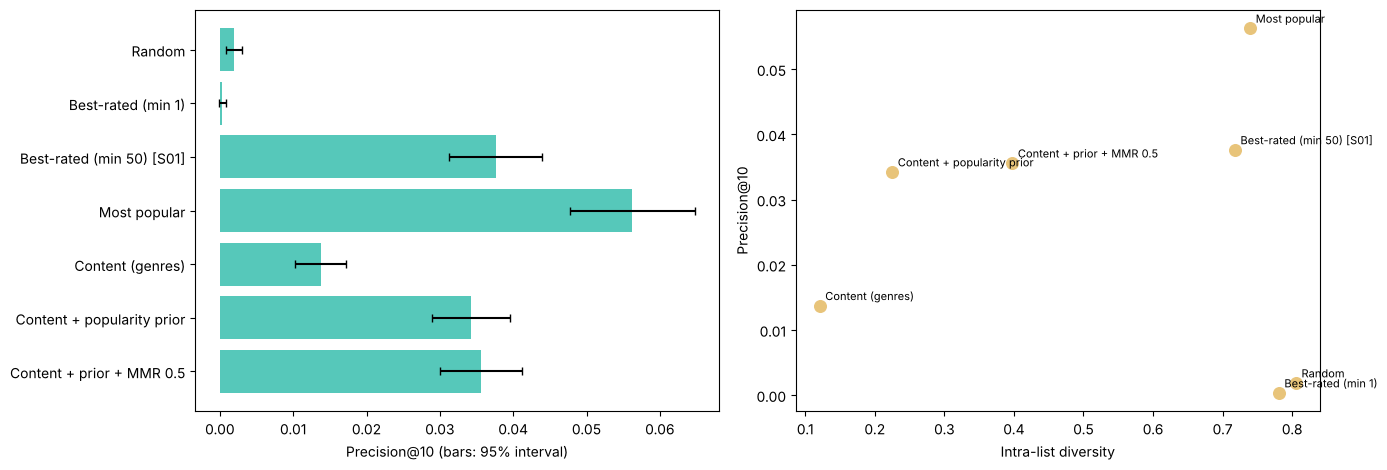

In [19]:
plot_results(results)

> **Reading the table.** Five things stand out, and only the first is the one
> the metrics were supposed to show.
>
> 1. **The non-personalised baseline wins on accuracy.** `Most popular` has the
>    best precision, recall and NDCG, and the paired test above says its lead
>    over every other model is far larger than the noise (|t| ≥ 4.8 against
>    all of them). A content-based model that uses nothing but the 19 MovieLens genres
>    simply has less information than "what everybody watched".
> 2. **`Best-rated (min 1)` is the trap of the session.** Its precision is
>    *below random* (0.0003 against 0.0019) while its novelty is the highest of
>    the table (9.2 bits): ranking by mean rating with no support threshold
>    fills the list with items rated 5.0 by a single user. Requiring 50 ratings
>    (the Session 01 baseline) multiplies its precision by a hundred. Same
>    metric, same formula, opposite conclusions — the eligibility rule matters
>    more than the ranking criterion.
> 3. **Accuracy and coverage are in direct conflict.** `Most popular` serves
>    1.2 % of the catalogue, `Random` 51 %. The two models with any claim to
>    both are the content ones: 9-12 % of the catalogue for a precision within
>    a factor of two of the best.
> 4. **Novelty is not a quality.** `Random` scores 7.5 bits and `Best-rated
>    (min 1)` 9.2, which only says they recommend items nobody has seen. A
>    beyond-accuracy metric is only readable *next to* an accuracy one.
> 5. **The popularity prior is what makes the content model work.** Raising
>    `pop_weight` from 0.001 to 0.3 multiplies precision by 2.5 (0.0137 →
>    0.0342) and diversity by 1.9. With genres only, hundreds of items share
>    the exact same vector; the prior breaks those ties with something
>    informative, which is already the hybrid idea of Session 05.
>
> The honest summary of this table is uncomfortable: **on this dataset, with
> these features, no personalised model beats showing everybody the most
> popular films.** What the beyond-accuracy columns add is *why* one might ship
> a personalised one anyway — a shelf that shows 1 % of the catalogue cannot
> sustain a catalogue.

## 9. Log to the comparison table

In [20]:
table = log_results("./comparison_table.csv", results)
table.tail(len(results))


,session,model,precision,precision_se,recall,ndcg,coverage,diversity,novelty,n_users
0,S04,Random,0.001864,0.000557,0.001111,0.002066,0.512733,0.805405,7.474381,590.0
1,S04,Best-rated (min 1),0.000339,0.000239,0.001713,0.000891,0.001577,0.780813,9.153004,590.0
2,S04,Best-rated (min 50) [S01],0.037627,0.003230,0.029730,0.049367,0.007640,0.717656,2.625480,590.0
3,S04,Most popular,0.056271,0.004362,0.051437,0.074273,0.011885,0.739612,1.520742,590.0
4,S04,Content (genres),0.013729,0.001762,0.012114,0.018443,0.116541,0.120710,5.688469,590.0
5,S04,Content + popularity prior,0.034237,0.002697,0.035136,0.048254,0.085253,0.225019,3.566207,590.0
6,S04,Content + prior + MMR 0.5,0.035593,0.002855,0.032855,0.049009,0.072763,0.397629,3.343625,590.0


> The table is appended to on every run: `comparison_table.csv` committed next
> to this notebook holds the seven rows of one clean run. The Session 03
> metrics (`validation_rmse`, `mean_predicted_top10`) live in that session's
> own table — the two sets of columns do not overlap, which is itself the
> point of question 4 of the next section: a rating-prediction model and a
> top-K pipeline do not measure the same thing.

## 10. Going further (open-ended)

Pick at least one, and **justify your conclusion with the standard errors**.

**1. The MMR trade-off.** Re-run the last model for several values of `lambda_` (for example 0.9, 0.7, 0.5, 0.3, 0.1) and plot precision against diversity. Is there a trade-off? Is any difference larger than the noise?

**2. Serendipity.** Implement `serendipity_at_k(recommended, relevant, expected, k)` as the number of relevant recommended items that are *not* in `expected` (for instance the 100 most popular items), divided by `k`. Which model is the most serendipitous?

**3. Which model would you ship?** Choose one model for a "top picks for you" shelf and another for a "discover something new" page. Defend each choice with at least three of the metrics above.

**4. Your Session 03 model.** What would it take to evaluate the latent-factor model from Session 03 with this pipeline? (Think about data, split and the `recommend` method before writing code.)

### Chosen topic — 1. The MMR trade-off

The question is whether trading relevance for diversity costs precision, and
whether the differences are larger than the noise. Two precisions measured on
the same users are **paired**, so comparing them through their separate
standard errors wastes information: the paired standard error of the
*difference* is the right ruler, and it is the one used in the conclusion
below.

In [21]:
def sweep_mmr(lambda_values: Sequence[float], n_candidates: int = 100) -> tuple[pd.DataFrame, dict[float, pd.DataFrame]]:
    """Evaluate the MMR re-ranker for several values of ``lambda_``.

    Parameters
    ----------
    lambda_values : sequence of float
        Values of the MMR trade-off to evaluate, in [0, 1].
    n_candidates : int, optional
        Number of base candidates re-ranked, passed to ``MMRReranker``.

    Returns
    -------
    summary : pandas.DataFrame
        One row per value of ``lambda_``, same columns as ``results``.
    per_user : dict of {float: pandas.DataFrame}
        Per-user metrics of each run, kept for the paired comparison.
    """
    summary, per_user_frames = {}, {}
    for lambda_ in lambda_values:
        model = MMRReranker(
            GenreContentRecommender(pop_weight=0.3), lambda_=lambda_, n_candidates=n_candidates
        ).fit(train, movies)
        per_user, rec_lists = evaluate_recommender(
            model, test, K, item_counts, n_train_users, item_vectors, item_index
        )
        summary[lambda_] = summarise_results(per_user, rec_lists, n_catalogue=len(items))
        per_user_frames[lambda_] = per_user
    frame = pd.DataFrame(summary).T
    frame.index.name = "lambda"
    return frame, per_user_frames


lambda_values = [0.9, 0.7, 0.5, 0.3, 0.1]
mmr_sweep, mmr_per_user = sweep_mmr(lambda_values)
mmr_sweep[["precision", "precision_se", "ndcg", "diversity", "novelty", "coverage"]].round(4)

,precision,precision_se,ndcg,diversity,novelty,coverage
lambda,,,,,,
0.9,0.0349,0.0028,0.0495,0.2811,3.4044,0.0800
0.7,0.0383,0.0029,0.0524,0.3665,3.2259,0.0707
0.5,0.0356,0.0029,0.0490,0.3976,3.3436,0.0728
0.3,0.0349,0.0028,0.0473,0.4069,3.4527,0.0769
0.1,0.0337,0.0028,0.0464,0.4091,3.5336,0.0798


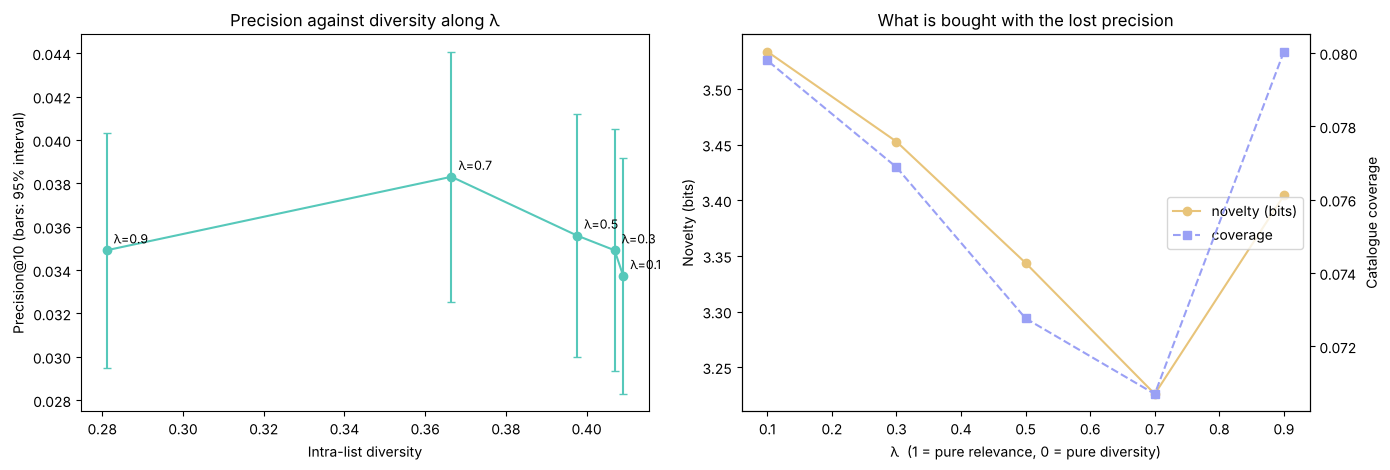

λ=0.9 vs λ=0.1, paired on the same users:
  Δprecision  = +0.0012 ± 0.0019 (SE)   t = +0.62   n = 590
  Δndcg       = +0.0031 ± 0.0026 (SE)   t = +1.21   n = 590
  Δdiversity  = -0.1280 ± 0.0039 (SE)   t = -33.20   n = 590

precision: best λ=0.7 (0.0383), worst λ=0.1 (0.0337)
paired Δprecision between them = +0.0046 ± 0.0016 (SE), t = +2.88


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].errorbar(mmr_sweep["diversity"], mmr_sweep["precision"],
                 yerr=1.96 * mmr_sweep["precision_se"], fmt="o-", color="#56c8ba", capsize=3)
for lambda_, row in mmr_sweep.iterrows():
    axes[0].annotate(f"λ={lambda_}", (row["diversity"], row["precision"]),
                     fontsize=9, xytext=(5, 5), textcoords="offset points")
axes[0].set_xlabel("Intra-list diversity")
axes[0].set_ylabel(f"Precision@{K} (bars: 95% interval)")
axes[0].set_title("Precision against diversity along λ")

axes[1].plot(mmr_sweep.index, mmr_sweep["novelty"], "o-", color="#e8c47a", label="novelty (bits)")
axes[1].set_xlabel("λ  (1 = pure relevance, 0 = pure diversity)")
axes[1].set_ylabel("Novelty (bits)")
twin = axes[1].twinx()
twin.plot(mmr_sweep.index, mmr_sweep["coverage"], "s--", color="#9aa0f5", label="coverage")
twin.set_ylabel("Catalogue coverage")
lines = axes[1].get_lines() + twin.get_lines()
axes[1].legend(lines, [line.get_label() for line in lines], loc="center right")
axes[1].set_title("What is bought with the lost precision")
plt.tight_layout()
plt.show()

print(f"λ=0.9 vs λ=0.1, paired on the same users:")
for column in ("precision", "ndcg", "diversity"):
    stats = paired_difference(mmr_per_user[0.9], mmr_per_user[0.1], column)
    print(f"  Δ{column:10s} = {stats['mean']:+.4f} ± {stats['se']:.4f} (SE)   t = {stats['t']:+.2f}   n = {stats['n']}")

best, worst = mmr_sweep["precision"].idxmax(), mmr_sweep["precision"].idxmin()
print(f"\nprecision: best λ={best} ({mmr_sweep.loc[best, 'precision']:.4f}), "
      f"worst λ={worst} ({mmr_sweep.loc[worst, 'precision']:.4f})")
stats = paired_difference(mmr_per_user[best], mmr_per_user[worst], "precision")
print(f"paired Δprecision between them = {stats['mean']:+.4f} ± {stats['se']:.4f} (SE), t = {stats['t']:+.2f}")

> **Conclusion — the trade-off exists, but not where one expects it.**
>
> | λ | Precision@10 | Diversity | Novelty (bits) | Coverage |
> |---|---|---|---|---|
> | 0.9 | 0.0349 | 0.281 | 3.40 | 0.080 |
> | **0.7** | **0.0383** | 0.367 | 3.23 | 0.071 |
> | 0.5 | 0.0356 | 0.398 | 3.34 | 0.073 |
> | 0.3 | 0.0349 | 0.407 | 3.45 | 0.077 |
> | 0.1 | 0.0337 | 0.409 | 3.53 | 0.080 |
>
> **Diversity responds monotonically to λ** (0.28 → 0.41, that is +45 %), and
> that movement is massively significant: paired between λ = 0.9 and λ = 0.1,
> Δdiversity = −0.128 ± 0.004, **t = −33**.
>
> **Precision does not.** Between the same two extremes,
> Δprecision = +0.0012 ± 0.0019, **t = 0.62**: the loss of accuracy one would
> expect from diversifying is *not distinguishable from the noise*. On the
> strength of those two numbers alone, 45 % of extra diversity is free.
>
> The curve is not flat either, and this is the interesting part: λ = 0.7
> is the **best** precision of the five, above λ = 0.9 (no re-ranking at all,
> in practice) and significantly above λ = 0.1
> (Δ = +0.0046 ± 0.0016, t = 2.88). A mild re-ranking *helps* accuracy here,
> which the mechanism explains: with 19 genres, hundreds of items carry the
> exact same TF-IDF vector, so the base ranking decides between clones by
> popularity alone; MMR's redundancy penalty spreads the list over several
> genre clusters, and a user's held-out items are rarely all in one cluster.
> Only strong diversification (λ ≤ 0.3) starts to cost something.
>
> **Two caveats I would not skip.** First, λ = 0.7 was *selected* as the best
> of five values, so its advantage is optimistically biased; with a Bonferroni
> correction over the ten pairwise comparisons, t = 2.88 (p ≈ 0.004) only just
> survives at the 5 % level. Second, novelty and coverage are **U-shaped** in
> λ, which is not a contradiction: at λ = 0.9 the lists follow the popularity
> prior, at λ = 0.1 they chase rare genre combinations, and in between they do
> a bit of both. A single metric would have hidden that; three of them
> together show it.
>
> Taken with the main table, the recommendation is λ ≈ 0.7: the only setting
> that improves accuracy *and* adds a third of a point of diversity over the
> un-reranked model.

---
**End of TP 04.**